<a href="https://colab.research.google.com/github/poojagupthaa14/OIBSIP/blob/main/pooja_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files

uploaded = files.upload()

Saving Online Retail.xlsx to Online Retail.xlsx


In [2]:
import pandas as pd

df = pd.read_excel('Online Retail.xlsx')

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
df.shape

(541909, 8)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [5]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [6]:
df.duplicated().sum()

np.int64(5268)

In [8]:
df_clean = df.drop_duplicates()

In [9]:
df_clean = df_clean.dropna(subset=['CustomerID'])

In [10]:
df_clean = df_clean[
    ~df_clean['InvoiceNo'].astype(str).str.startswith('C')
]

In [11]:
df_clean = df_clean[
    (df_clean['Quantity'] > 0) &
    (df_clean['UnitPrice'] > 0)
]

In [12]:
df_clean.shape

(392692, 8)

In [13]:
df_clean.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,0
Country,0


In [14]:
df_clean['TotalAmount'] = df_clean['Quantity'] * df_clean['UnitPrice']

In [15]:
import pandas as pd

reference_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)

print(reference_date)

2011-12-10 12:50:00


In [16]:
rfm = df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalAmount': 'sum'
})

In [17]:
rfm.columns = ['Recency', 'Frequency', 'Monetary']

In [18]:
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [19]:
rfm.shape

(4338, 3)

In [20]:
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [21]:
from sklearn.preprocessing import StandardScaler

In [22]:
scaler = StandardScaler()

In [23]:
rfm_scaled = scaler.fit_transform(rfm)

In [24]:
print(rfm_scaled[:5])

[[ 2.33457414 -0.4250965   8.36301037]
 [-0.90534032  0.3544168   0.2516989 ]
 [-0.17535959 -0.03533985 -0.02798783]
 [-0.73534481 -0.4250965  -0.03240559]
 [ 2.17457836 -0.4250965  -0.19081155]]


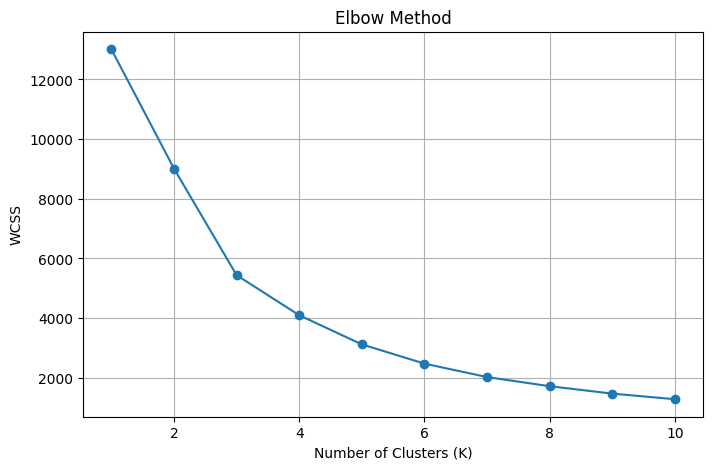

In [26]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.grid()
plt.show()

**Chart Title:** Elbow Method for Optimal Number of Clusters

**Description:** This graph is used to identify the optimal number of clusters (K) for customer segmentation. It shows how WCSS changes as the number of clusters increases.

**Observation:** As the number of clusters increases, WCSS decreases. The elbow point indicates a suitable number of clusters for grouping customers based on their purchasing behaviour.

In [27]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

rfm.head()

,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346.0,326,1,77183.60,3
12347.0,2,7,4310.00,0
12348.0,75,4,1797.24,0
12349.0,19,1,1757.55,0
12350.0,310,1,334.40,1


**Observation:** K-Means clustering successfully grouped customers into different clusters based on their purchasing behaviour. Each customer was assigned a cluster number, helping identify different customer segments for further analysis.

In [28]:
cluster_analysis = rfm.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].mean()

print(cluster_analysis)

            Recency  Frequency       Monetary
Cluster                                      
0         43.702685   3.682711    1353.625312
1        248.075914   1.552015     478.848773
2          7.384615  82.538462  127187.959231
3         15.500000  22.333333   12690.500392


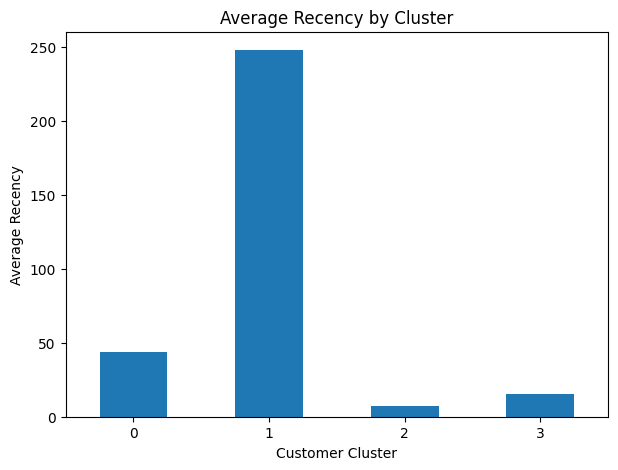

In [29]:
cluster_analysis['Recency'].plot(kind='bar', figsize=(7,5))

plt.title('Average Recency by Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Average Recency')
plt.xticks(rotation=0)
plt.show()

**Chart Title:** Average Recency by Cluster

**Description:** This bar chart compares the average Recency values across different customer clusters. It helps identify how recently customers from each group made their purchases.

**Observation:** The chart shows differences in purchasing recency among customer clusters. Customers with lower Recency values have purchased more recently, while higher values indicate customers who have not purchased for a longer period.

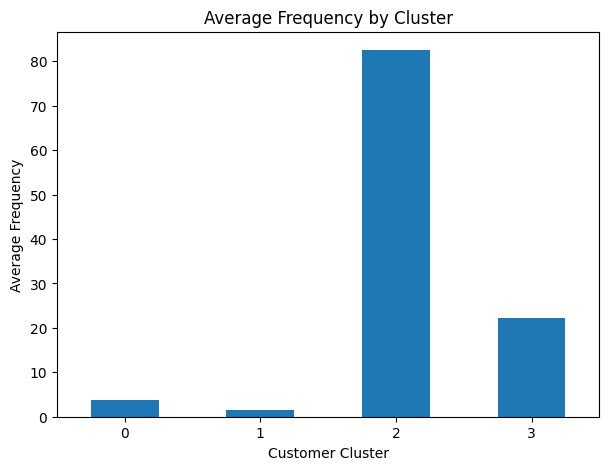

In [30]:
cluster_analysis['Frequency'].plot(kind='bar', figsize=(7,5))

plt.title('Average Frequency by Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Average Frequency')
plt.xticks(rotation=0)
plt.show()

**Chart Title:** Average Frequency by Cluster

**Description:** This bar chart compares the average purchase frequency of customers across different clusters. It helps identify which customer groups make purchases more frequently.

**Observation:** The chart highlights differences in purchasing frequency among customer clusters. Customers with higher frequency values make purchases more often, while lower values indicate less frequent purchasing behaviour.

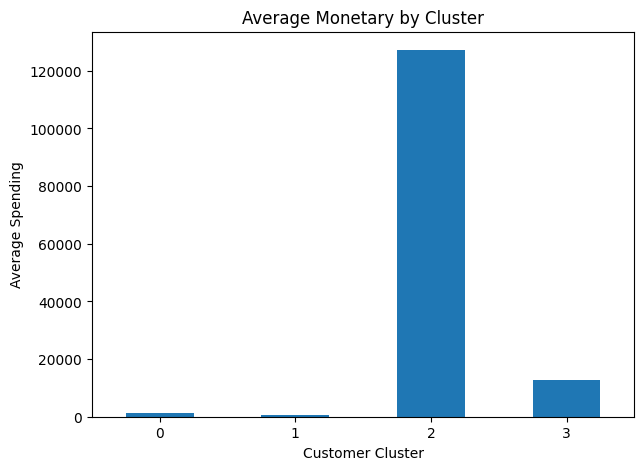

In [31]:
cluster_analysis['Monetary'].plot(kind='bar', figsize=(7,5))

plt.title('Average Monetary by Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Average Spending')
plt.xticks(rotation=0)
plt.show()

**Chart Title:** Average Monetary by Cluster

**Description:** This bar chart compares the average spending of customers across different clusters. It helps identify which customer groups contribute more to the overall revenue.

**Observation:** The chart highlights differences in spending behaviour among customer clusters. Customers with higher Monetary values contribute more revenue, while lower values indicate customers who spend less.

In [32]:
print(cluster_analysis.round(2))

         Recency  Frequency   Monetary
Cluster                               
0          43.70       3.68    1353.63
1         248.08       1.55     478.85
2           7.38      82.54  127187.96
3          15.50      22.33   12690.50


**Business Insights:**

1. **Cluster 0 – Regular Customers:** These customers make purchases occasionally and contribute a moderate amount to revenue. Businesses can encourage them to purchase more frequently through offers and discounts.

2. **Cluster 1 – Inactive Customers:** These customers have not purchased recently and have low purchasing frequency. Businesses can use promotional campaigns and special offers to encourage them to return.

3. **Cluster 2 – High-Value Customers:** These customers purchase very frequently and contribute the highest revenue. Businesses should focus on retaining these customers through loyalty rewards and exclusive benefits.

4. **Cluster 3 – Loyal Customers:** These customers purchase regularly and contribute significantly to revenue. Businesses can maintain their loyalty through personalized offers and customer engagement.

**Conclusion:**

Customer segmentation was successfully performed using RFM analysis and the K-Means clustering algorithm. Customers were divided into four different clusters based on their Recency, Frequency and Monetary values.

The analysis helped identify regular, inactive, high-value and loyal customers. These insights can help businesses develop targeted marketing strategies, improve customer retention and increase overall revenue.